# Diabetic Retinopathy Classification

**Project context:** Collaborative university coursework.

Binary classification of severe (original classes 3–4) versus non-severe (classes 0–2) diabetic retinopathy. This notebook compares a pretrained ResNet-18 and a pretrained Vision Transformer with LoRA.

Saved outputs record 3,264 training, 816 validation and 500 test images. The models use different preprocessing and training schedules; this is a comparison of complete setups rather than an isolated test of LoRA. See README.md for the recorded results and reproducibility limits.

Author identifiers and local metadata were removed. Aggregate outputs and plots were retained. Retinal-image outputs were withheld pending source-image redistribution review; the visualization code is unchanged.


In [ ]:
!pip install "numpy<2.0"

In [ ]:
#!pip -q install transformers peft grad-cam

import os, time, copy, random
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset

from torchvision import datasets, transforms, models

# Transformer (Hugging Face)
from transformers import ViTForImageClassification, ViTImageProcessor
from peft import LoraConfig, get_peft_model

# xAI
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## 1. Data preparation - Binary Mapping (5 classes → 2 classes)

We use `ImageFolder` with a `target_transform` to map labels:
- `0,1,2 → 0` (non-severe)
- `3,4 → 1` (severe)

In [ ]:
base_dir = "DR_data_cropped_classes/DR_data_cropped_classes"
train_dir = os.path.join(base_dir, "train")
test_dir  = os.path.join(base_dir, "test")

assert os.path.isdir(train_dir), f"Train directory not found: {train_dir}"
assert os.path.isdir(test_dir),  f"Test directory not found: {test_dir}"

def map_labels(lbl: int) -> int:
    return 1 if lbl >= 3 else 0

### Transforms

- Training: mild augmentation (no vertical flips; limited jitter/rotation).
- Validation/Test: deterministic resize + center crop.

In [ ]:
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],[0.229, 0.224, 0.225]),
])

val_test_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],[0.229, 0.224, 0.225]),
])

### Datasets, train/validation split and loaders

The code makes a seeded random 80/20 image-level split of the training folder. It does not stratify or group by patient. Saved counts are 3,264 train, 816 validation and 500 test images. Checkpoints are selected on validation accuracy; test images are subsequently reused for timing and explanation examples.


In [ ]:
# Two dataset views for same images: augmentation for training, deterministic for validation
full_train_data_aug  = datasets.ImageFolder(train_dir, transform=train_transforms,   target_transform=map_labels)
full_train_data_eval = datasets.ImageFolder(train_dir, transform=val_test_transforms, target_transform=map_labels)
test_ds              = datasets.ImageFolder(test_dir,  transform=val_test_transforms, target_transform=map_labels)

print("class_to_idx:", full_train_data_aug.class_to_idx)
print("classes:", full_train_data_aug.classes)

# Split
num_train = len(full_train_data_aug)
indices = np.arange(num_train)
np.random.shuffle(indices)
split = int(0.2 * num_train)

val_idx = indices[:split]
train_idx = indices[split:]

train_ds = Subset(full_train_data_aug,  train_idx)
val_ds   = Subset(full_train_data_eval, val_idx)

BATCH_SIZE = 32
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

def count_labels_from_subset(subset):
    c = Counter()
    for i in subset.indices:
        _, y = subset.dataset[i]
        c[int(y)] += 1
    return c

train_counts = count_labels_from_subset(train_ds)
val_counts   = count_labels_from_subset(val_ds)
test_counts  = Counter([int(test_ds[i][1]) for i in range(len(test_ds))])

print("Train counts:", train_counts)
print("Val counts:", val_counts)
print("Test counts:", test_counts)

class_to_idx: {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4}
classes: ['0', '1', '2', '3', '4']
Train counts: Counter({0: 2138, 1: 1126})
Val counts: Counter({0: 562, 1: 254})
Test counts: Counter({0: 300, 1: 200})


## 2. Helper utilities (training, evaluation, plots)

In [ ]:
def train_one_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler=None,
    epochs=15,
    name="model"
):
    best_acc = 0.0
    best_wts = copy.deepcopy(model.state_dict())

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_acc": [],
        "lr": [],
    }

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * x.size(0)

        train_loss = running_loss / len(train_loader.dataset)

        # Validation
        model.eval()
        val_loss = 0.0
        correct, total = 0, 0

        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                logits = model(x)
                loss = criterion(logits, y)
                val_loss += loss.item() * x.size(0)
                pred = logits.argmax(dim=1)
                correct += (pred == y).sum().item()
                total += y.size(0)

        val_loss = val_loss / len(val_loader.dataset)
        val_acc = correct / total

        if scheduler is not None:
            scheduler.step()

        lr_now = optimizer.param_groups[0]["lr"]
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(lr_now)

        print(f"Epoch {epoch+1:02d}/{epochs} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.4f} | lr={lr_now:.6f}")

        if val_acc > best_acc:
            best_acc = val_acc
            best_wts = copy.deepcopy(model.state_dict())
            torch.save(best_wts, f"best_{name}.pth")

    model.load_state_dict(best_wts)
    print(f"Best Val Acc ({name}): {best_acc:.4f}")
    return model, history

def eval_logits(model, loader):
    model.eval()
    ys, preds = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            logits = model(x)
            pred = logits.argmax(dim=1).cpu().numpy()
            preds.extend(pred)
            ys.extend(y.numpy())
    return np.array(ys), np.array(preds)

def show_report(name, y, pred):
    acc = accuracy_score(y, pred)
    print(f"\n=== {name} TEST RESULTS ===")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y, pred, target_names=["non-severe(0)", "severe(1)"]))
    cm = confusion_matrix(y, pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{name} Confusion Matrix (Test)")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()
    return acc, cm

def plot_history(history, title):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(12,4))

    plt.subplot(1,2,1)
    plt.plot(epochs, history["train_loss"], label="train loss")
    plt.plot(epochs, history["val_loss"], label="val loss")
    plt.title(f"{title} Loss")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(epochs, history["val_acc"], label="val acc")
    plt.title(f"{title} Validation Accuracy")
    plt.xlabel("epoch")
    plt.ylabel("acc")
    plt.legend()

    plt.tight_layout()
    plt.show()

def measure_inference_ms_per_image(model, loader, warmup_batches=3):
    model.eval()

    
    with torch.no_grad():
        for i, (x, _) in enumerate(loader):
            x = x.to(device)
            _ = model(x)
            if i >= warmup_batches-1:
                break

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.time()
    n = 0
    with torch.no_grad():
        for x, _ in loader:
            x = x.to(device)
            _ = model(x)
            n += x.size(0)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end = time.time()
    return (end - start) / n * 1000.0

import seaborn as sns

## 3. Model 1 - CNN (ResNet-18)

**Little-data techniques used:**
- ImageNet pretrained weights (transfer learning)
- Data augmentation
- Learning-rate scheduler
- Early model selection via validation accuracy

We keep evaluation on the *test* set only at the end .

In [ ]:
# Build ResNet-18
resnet = models.resnet18(weights='IMAGENET1K_V1')
resnet.fc = nn.Linear(resnet.fc.in_features, 2)
resnet = resnet.to(device)

# Class weights (helps reduce false negatives for severe)
# weight for class1 ≈ count0/count1
w1 = train_counts[0] / max(1, train_counts[1])
class_weights = torch.tensor([1.0, w1], device=device, dtype=torch.float)
print("ResNet class_weights:", class_weights.tolist())

criterion_resnet = nn.CrossEntropyLoss(weight=class_weights)

optimizer_resnet = optim.AdamW(resnet.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler_resnet = optim.lr_scheduler.CosineAnnealingLR(optimizer_resnet, T_max=15)

resnet, hist_resnet = train_one_model(
    resnet, train_loader, val_loader,
    criterion_resnet, optimizer_resnet,
    scheduler=scheduler_resnet,
    epochs=15,
    name="resnet18"
)

ResNet class_weights: [1.0, 1.8987566232681274]
Epoch 01/15 | train_loss=0.4674 | val_loss=0.4885 | val_acc=0.8297 | lr=0.000099
Epoch 02/15 | train_loss=0.3580 | val_loss=0.4950 | val_acc=0.8002 | lr=0.000096
Epoch 03/15 | train_loss=0.3208 | val_loss=0.4524 | val_acc=0.8321 | lr=0.000090
Epoch 04/15 | train_loss=0.2920 | val_loss=0.3828 | val_acc=0.8407 | lr=0.000083
Epoch 05/15 | train_loss=0.2452 | val_loss=0.5043 | val_acc=0.8419 | lr=0.000075
Epoch 06/15 | train_loss=0.2111 | val_loss=0.5054 | val_acc=0.8333 | lr=0.000065
Epoch 07/15 | train_loss=0.1393 | val_loss=0.4873 | val_acc=0.8150 | lr=0.000055
Epoch 08/15 | train_loss=0.1268 | val_loss=0.4900 | val_acc=0.8431 | lr=0.000045
Epoch 09/15 | train_loss=0.1064 | val_loss=0.5166 | val_acc=0.8603 | lr=0.000035
Epoch 10/15 | train_loss=0.0840 | val_loss=0.5529 | val_acc=0.8529 | lr=0.000025
Epoch 11/15 | train_loss=0.0553 | val_loss=0.5334 | val_acc=0.8419 | lr=0.000017
Epoch 12/15 | train_loss=0.0517 | val_loss=0.5781 | val_acc=0

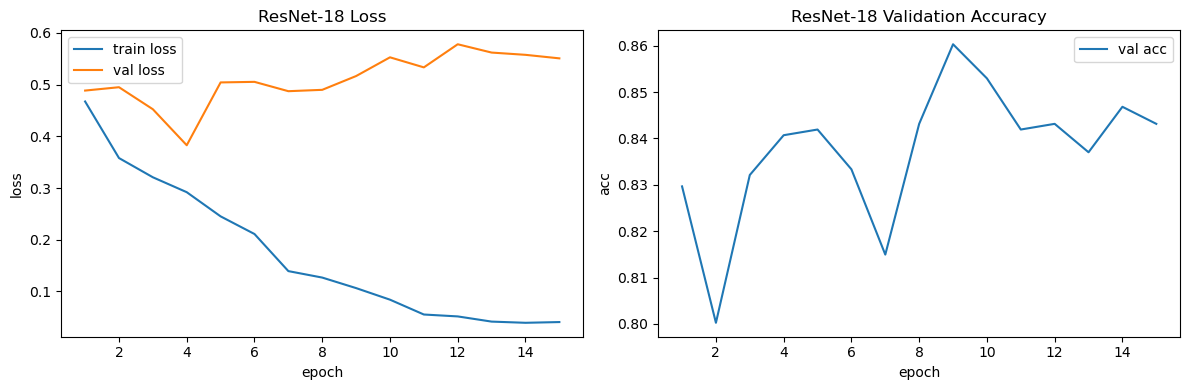

In [ ]:
plot_history(hist_resnet, "ResNet-18")

### ResNet-18: Final Test Evaluation + Inference Time


=== ResNet-18 TEST RESULTS ===
Accuracy: 0.8680
               precision    recall  f1-score   support

non-severe(0)       0.86      0.93      0.89       300
    severe(1)       0.88      0.78      0.83       200

     accuracy                           0.87       500
    macro avg       0.87      0.85      0.86       500
 weighted avg       0.87      0.87      0.87       500



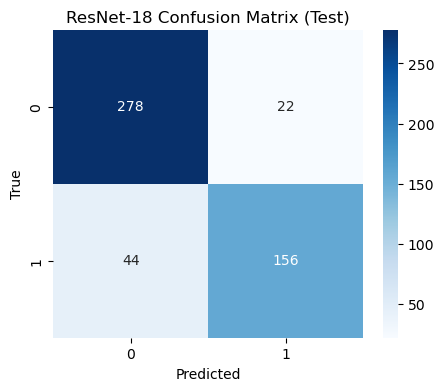

ResNet-18 avg inference time: 5.81 ms / image


In [ ]:
y_r, p_r = eval_logits(resnet, test_loader)
acc_r, cm_r = show_report("ResNet-18", y_r, p_r)

ms_r = measure_inference_ms_per_image(resnet, test_loader)
print(f"ResNet-18 avg inference time: {ms_r:.2f} ms / image")

## 4. Misclassification analysis (5 examples)

We show five misclassified test images for the CNN and discuss likely reasons for failure.

In [ ]:
def get_misclassified_indices(model, dataset, max_examples=5):
    model.eval()
    wrong = []
    with torch.no_grad():
        for idx in range(len(dataset)):
            x, y = dataset[idx]
            x_in = x.unsqueeze(0).to(device)
            pred = model(x_in).argmax(dim=1).item()
            if pred != int(y):
                wrong.append((idx, int(y), pred))
                if len(wrong) >= max_examples:
                    break
    return wrong

def show_images(dataset, triplets, title):
    plt.figure(figsize=(12, 3*len(triplets)))
    for i, (idx, y, pred) in enumerate(triplets):
        x, _ = dataset[idx]
        img = x.detach().cpu().permute(1,2,0).numpy()
        mean = np.array([0.485,0.456,0.406])
        std  = np.array([0.229,0.224,0.225])
        img = (img * std) + mean
        img = np.clip(img, 0, 1)

        plt.subplot(len(triplets), 1, i+1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"index={idx} | true={y} pred={pred}")
    plt.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()

wrong_r = get_misclassified_indices(resnet, test_ds, max_examples=5)
print("ResNet misclassified:", wrong_r)
show_images(test_ds, wrong_r, "ResNet-18: 5 misclassified test images")

**Error-analysis scope:** The retained output code selects the first five errors in dataset order. In the saved run all five were false positives, so this selection does not characterize severe false negatives. Blur, illumination, crop effects and borderline grades are hypotheses to investigate, not verified causes. Source-image outputs are withheld pending redistribution review.


## 5. xAI for CNN - Grad-CAM on 5 examples

We use Grad-CAM to inspect whether the CNN focuses on meaningful retinal regions (vessels/lesions) or spurious artifacts (borders/background).

In [ ]:
def gradcam_resnet_examples(model, dataset, n=5):
    model.eval()
    target_layer = model.layer4[-1]  # ResNet-18 final block
    cam = GradCAM(model=model, target_layers=[target_layer])

    idxs = np.random.choice(len(dataset), size=n, replace=False)

    plt.figure(figsize=(10, 2.6*n))
    for i, idx in enumerate(idxs):
        x, y = dataset[idx]
        x_in = x.unsqueeze(0).to(device)

        targets = [ClassifierOutputTarget(int(y))]
        grayscale_cam = cam(input_tensor=x_in, targets=targets)[0]

        img = x.detach().cpu().permute(1,2,0).numpy()
        mean = np.array([0.485,0.456,0.406])
        std  = np.array([0.229,0.224,0.225])
        img = (img * std) + mean
        img = np.clip(img, 0, 1)

        cam_img = show_cam_on_image(img, grayscale_cam, use_rgb=True)

        plt.subplot(n, 2, 2*i+1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"Original (true={int(y)})")

        plt.subplot(n, 2, 2*i+2)
        plt.imshow(cam_img)
        plt.axis("off")
        plt.title("Grad-CAM")

    plt.tight_layout()
    plt.show()

gradcam_resnet_examples(resnet, test_ds, n=5)

**Interpretation limits:** Grad-CAM is calculated for the ground-truth class in this implementation. It provides a qualitative visualization, not proof that the model detects lesions, ignores all background artifacts or is clinically safe. Image examples were withheld; the implementation is preserved for use with appropriately licensed images.


## 6. Model 2 - Vision Transformer (ViT) with LoRA 

**Little-data techniques used:**
- ImageNet-pretrained ViT backbone
- LoRA (Parameter-Efficient Fine-Tuning) on attention projections
- Class-weighted loss (reduce severe false negatives)
- Validation-based model selection

We use Hugging Face preprocessing (`ViTImageProcessor`) to match the pretrained ViT input normalization.

In [ ]:
# HF processor
vit_name = "google/vit-base-patch16-224-in21k"
processor = ViTImageProcessor.from_pretrained(vit_name)

# Raw datasets with binary label mapping
train_raw = datasets.ImageFolder(train_dir, transform=None, target_transform=map_labels)
test_raw  = datasets.ImageFolder(test_dir,  transform=None, target_transform=map_labels)

train_raw_subset = Subset(train_raw, train_idx)
val_raw_subset   = Subset(train_raw, val_idx)

class ViTFolderDataset(torch.utils.data.Dataset):
    def __init__(self, subset, processor):
        self.subset = subset
        self.processor = processor

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, i):
        img, label = self.subset[i]  # PIL image, int label
        enc = self.processor(images=img, return_tensors="pt")
        pixel_values = enc["pixel_values"].squeeze(0)  # [3,224,224]
        return pixel_values, torch.tensor(label, dtype=torch.long)

train_ds_vit = ViTFolderDataset(train_raw_subset, processor)
val_ds_vit   = ViTFolderDataset(val_raw_subset, processor)
test_ds_vit  = ViTFolderDataset(test_raw, processor)

train_loader_vit = DataLoader(train_ds_vit, batch_size=16, shuffle=True,  num_workers=2, pin_memory=True)
val_loader_vit   = DataLoader(val_ds_vit,   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader_vit  = DataLoader(test_ds_vit,  batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# class weights from train subset
cnt_v = Counter()
for _, y in train_ds_vit:
    cnt_v[int(y.item())] += 1
w1_v = cnt_v[0] / max(1, cnt_v[1])
class_weights_vit = torch.tensor([1.0, w1_v], device=device, dtype=torch.float)
print("ViT train counts:", cnt_v, "class_weights:", class_weights_vit.tolist())

ViT train counts: Counter({0: 2138, 1: 1126}) class_weights: [1.0, 1.8987566232681274]


In [ ]:
vit = ViTForImageClassification.from_pretrained(
    vit_name,
    num_labels=2,
    ignore_mismatched_sizes=True
)

# LoRA config: apply to attention query/value projections
lora_cfg = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["query", "value"],
    lora_dropout=0.05,
    bias="none",
    modules_to_save=["classifier"],
)

vit_lora = get_peft_model(vit, lora_cfg).to(device)
vit_lora.print_trainable_parameters()

criterion_vit = nn.CrossEntropyLoss(weight=class_weights_vit)
optimizer_vit = optim.AdamW(vit_lora.parameters(), lr=2e-4, weight_decay=0.01)
scheduler_vit = optim.lr_scheduler.CosineAnnealingLR(optimizer_vit, T_max=10)

def train_vit_lora(model, train_loader, val_loader, epochs=10, name="vit_lora"):
    best_acc = 0.0
    best_wts = copy.deepcopy(model.state_dict())
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer_vit.zero_grad()
            logits = model(pixel_values=x).logits
            loss = criterion_vit(logits, y)
            loss.backward()
            optimizer_vit.step()
            running_loss += loss.item() * x.size(0)

        scheduler_vit.step()
        train_loss = running_loss / len(train_loader.dataset)

        # validation
        model.eval()
        val_loss = 0.0
        correct, total = 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                logits = model(pixel_values=x).logits
                loss = criterion_vit(logits, y)
                val_loss += loss.item() * x.size(0)
                pred = logits.argmax(dim=1)
                correct += (pred == y).sum().item()
                total += y.size(0)

        val_loss /= len(val_loader.dataset)
        val_acc = correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1:02d}/{epochs} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.4f}")

        if val_acc > best_acc:
            best_acc = val_acc
            best_wts = copy.deepcopy(model.state_dict())
            torch.save(best_wts, f"best_{name}.pth")

    model.load_state_dict(best_wts)
    print(f"Best Val Acc ({name}): {best_acc:.4f}")
    return model, history

vit_lora, hist_vit = train_vit_lora(vit_lora, train_loader_vit, val_loader_vit, epochs=10, name="vit_lora")

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 296,450 || all params: 86,096,644 || trainable%: 0.3443
Epoch 01/10 | train_loss=0.5192 | val_loss=0.4257 | val_acc=0.8321
Epoch 02/10 | train_loss=0.3723 | val_loss=0.4341 | val_acc=0.7880
Epoch 03/10 | train_loss=0.3240 | val_loss=0.4210 | val_acc=0.8480
Epoch 04/10 | train_loss=0.2869 | val_loss=0.4112 | val_acc=0.8321
Epoch 05/10 | train_loss=0.2549 | val_loss=0.4236 | val_acc=0.8309
Epoch 06/10 | train_loss=0.2200 | val_loss=0.4475 | val_acc=0.8223
Epoch 07/10 | train_loss=0.1934 | val_loss=0.4368 | val_acc=0.8235
Epoch 08/10 | train_loss=0.1680 | val_loss=0.4704 | val_acc=0.8309
Epoch 09/10 | train_loss=0.1539 | val_loss=0.4791 | val_acc=0.8346
Epoch 10/10 | train_loss=0.1456 | val_loss=0.4823 | val_acc=0.8333
Best Val Acc (vit_lora): 0.8480


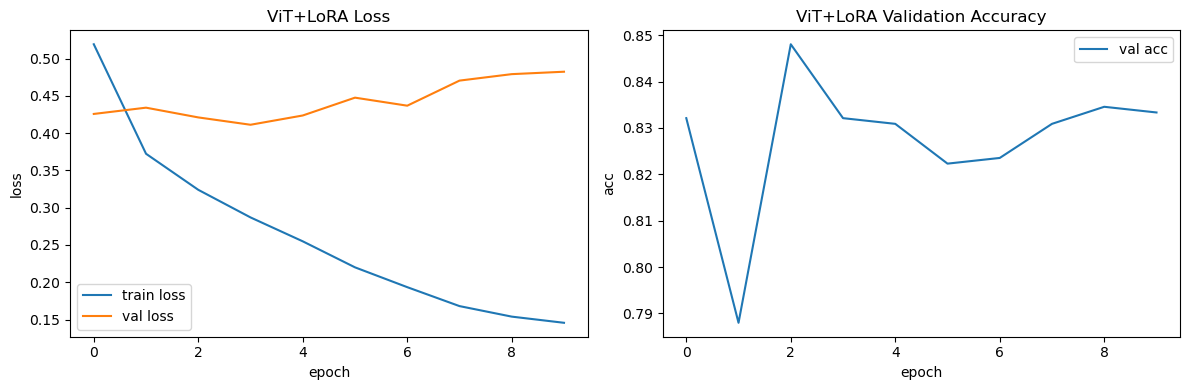

In [ ]:
# Plot ViT training curves
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(hist_vit["train_loss"], label="train loss")
plt.plot(hist_vit["val_loss"], label="val loss")
plt.title("ViT+LoRA Loss")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend()

plt.subplot(1,2,2)
plt.plot(hist_vit["val_acc"], label="val acc")
plt.title("ViT+LoRA Validation Accuracy")
plt.xlabel("epoch"); plt.ylabel("acc"); plt.legend()

plt.tight_layout()
plt.show()

### ViT+LoRA: Final Test Evaluation + Inference Time


ViT+LoRA TEST Accuracy: 0.8820
               precision    recall  f1-score   support

non-severe(0)       0.88      0.93      0.90       300
    severe(1)       0.89      0.81      0.85       200

     accuracy                           0.88       500
    macro avg       0.88      0.87      0.88       500
 weighted avg       0.88      0.88      0.88       500



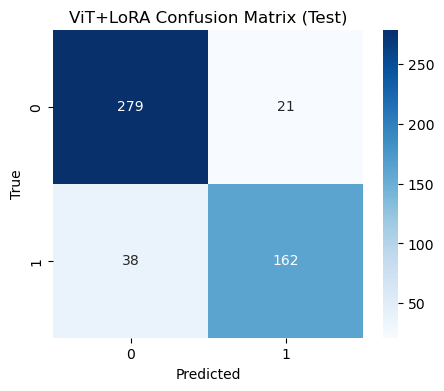

ViT+LoRA avg inference time: 7.29 ms / image


In [ ]:
def eval_vit(model, loader):
    model.eval()
    ys, preds = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            logits = model(pixel_values=x).logits
            pred = logits.argmax(dim=1).cpu().numpy()
            preds.extend(pred)
            ys.extend(y.numpy())
    return np.array(ys), np.array(preds)

y_v, p_v = eval_vit(vit_lora, test_loader_vit)
acc_v = accuracy_score(y_v, p_v)
print(f"\nViT+LoRA TEST Accuracy: {acc_v:.4f}")
print(classification_report(y_v, p_v, target_names=["non-severe(0)", "severe(1)"]))

cm_v = confusion_matrix(y_v, p_v)
plt.figure(figsize=(5,4))
sns.heatmap(cm_v, annot=True, fmt="d", cmap="Blues")
plt.title("ViT+LoRA Confusion Matrix (Test)")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.show()

ms_v = measure_inference_ms_per_image(vit_lora, test_loader_vit)
print(f"ViT+LoRA avg inference time: {ms_v:.2f} ms / image")

## 7. xAI for Transformer - Attention maps on 5 examples
We visualize attention from the CLS token to patch tokens for the last transformer layer.

In [ ]:
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

try:
    vit_lora.set_attn_implementation("eager")
except AttributeError:
    if hasattr(vit_lora, "config"):
        vit_lora.config.attn_implementation = "eager"
    if hasattr(vit_lora, "base_model") and hasattr(vit_lora.base_model, "config"):
        vit_lora.base_model.config.attn_implementation = "eager"


def vit_attention_examples(model, vit_dataset, n=5):
    model.eval()
    n = min(n, len(vit_dataset))
    idxs = np.random.choice(len(vit_dataset), size=n, replace=False)

    fig, axes = plt.subplots(n, 2, figsize=(10, 4*n))
    if n == 1: axes = np.array([axes]) 
    with torch.no_grad():
        for i, idx in enumerate(idxs):
            x, y = vit_dataset[idx]
            x_in = x.unsqueeze(0).to(device)

            out = model(pixel_values=x_in, output_attentions=True)
            pred = out.logits.argmax(dim=1).item()

            if out.attentions is None:
                print("FEHLER: 'out.attentions' ist immer noch None. Der Fix oben hat nicht geklappt.")
                break

            
            att = out.attentions[-1][0].mean(dim=0)  
            
            cls_att = att[0, 1:]  
            
            grid_size = int(np.sqrt(cls_att.shape[0]))
            att_map = cls_att.reshape(grid_size, grid_size).cpu().numpy()
            
            att_map = cv2.resize(att_map, (224, 224))
            att_map = (att_map - att_map.min()) / (att_map.max() - att_map.min() + 1e-8)

            img = x.detach().cpu().permute(1,2,0).numpy()
            mean = np.array([0.485,0.456,0.406])
            std  = np.array([0.229,0.224,0.225])
            img = (img * std) + mean
            img = np.clip(img, 0, 1)

            # Plot 1: Original
            axes[i,0].imshow(img)
            axes[i,0].axis("off")
            axes[i,0].set_title(f"True={int(y)} | Pred={pred}")

            # Plot 2: Heatmap Overlay
            axes[i,1].imshow(img)
            axes[i,1].imshow(att_map, cmap="jet", alpha=0.5) # Alpha macht es transparent
            axes[i,1].axis("off")
            axes[i,1].set_title("Attention Map (Model Focus)")

    plt.tight_layout()
    plt.show()

vit_attention_examples(vit_lora, test_ds_vit, n=5)

**Interpretation limits:** These are head-averaged final-layer CLS-to-patch attention maps. They are not directly comparable to class-targeted CNN Grad-CAM and do not establish the causal basis of a prediction. Any apparent attention to image borders is a hypothesis requiring further testing. Image examples are withheld pending redistribution review.


## 8. Results summary



In [ ]:
import pandas as pd 
df = pd.DataFrame([
    {"Model": "ResNet-18", "Test Acc": float(acc_r), "Avg ms/img": float(ms_r),
     "TN": int(cm_r[0,0]), "FP": int(cm_r[0,1]), "FN": int(cm_r[1,0]), "TP": int(cm_r[1,1])},
    {"Model": "ViT+LoRA",  "Test Acc": float(acc_v), "Avg ms/img": float(ms_v),
     "TN": int(cm_v[0,0]), "FP": int(cm_v[0,1]), "FN": int(cm_v[1,0]), "TP": int(cm_v[1,1])},
])


# Sensitivity: Wie viele Kranke haben wir gefunden? 
df["Sensitivity"] = df["TP"] / (df["TP"] + df["FN"])

# Specificity: Wie viele Gesunde haben wir korrekt erkannt?
df["Specificity"] = df["TN"] / (df["TN"] + df["FP"])

# F1-Score: Die Balance aus Precision und Recall
precision = df["TP"] / (df["TP"] + df["FP"])
df["F1-Score"] = 2 * (precision * df["Sensitivity"]) / (precision + df["Sensitivity"])

df_final = df[["Model", "Test Acc", "Sensitivity", "Specificity", "F1-Score", "Avg ms/img", "TP", "FN", "FP", "TN"]]

In [ ]:
def highlight_max(s):
    '''Hebt den höchsten Wert (grün) hervor'''
    is_max = s == s.max()
    return ['background-color: #d6f5d6' if v else '' for v in is_max]

def highlight_min(s):
    '''Hebt den niedrigsten Wert (grün bei Zeit, rot bei Fehlern) hervor'''
    is_min = s == s.min()
    return ['background-color: #d6f5d6' if v else '' for v in is_min]

styled_df = df_final.style.format({
    "Test Acc": "{:.2%}",
    "Sensitivity": "{:.2%}",
    "Specificity": "{:.2%}",
    "F1-Score": "{:.2%}",
    "Avg ms/img": "{:.2f} ms"
}).apply(highlight_max, subset=["Test Acc", "Sensitivity", "Specificity", "F1-Score"]) \
  .apply(highlight_min, subset=["Avg ms/img"]) \
  .hide(axis="index") \
  .set_caption("🏆 Model Performance Comparison")

styled_df

Model,Test Acc,Sensitivity,Specificity,F1-Score,Avg ms/img,TP,FN,FP,TN
ResNet-18,86.80%,78.00%,92.67%,82.54%,5.81 ms,156,44,22,278
ViT+LoRA,88.20%,81.00%,93.00%,84.60%,7.29 ms,162,38,21,279


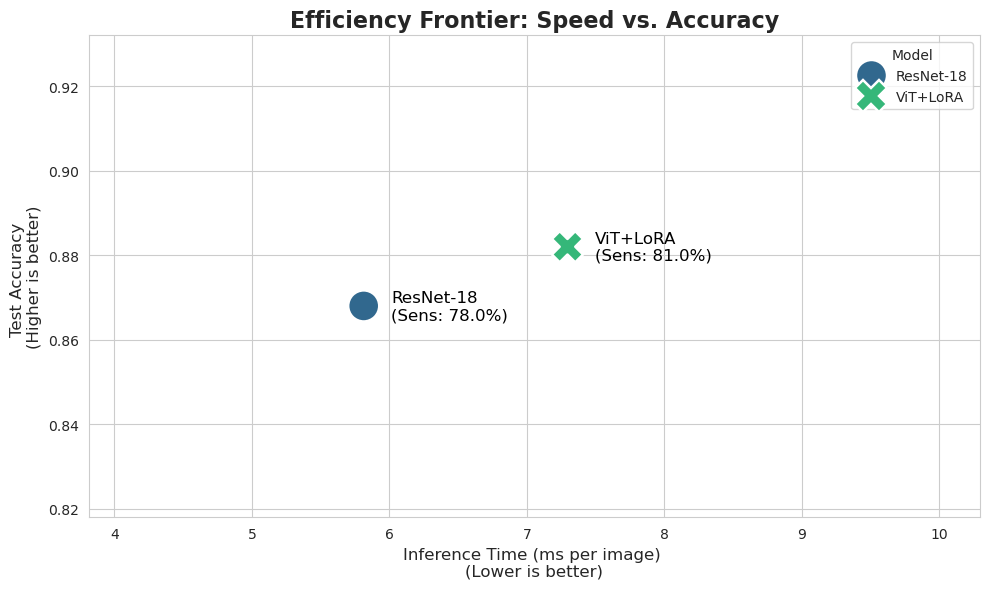

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Design-Einstellungen 
sns.set_style("whitegrid")
plt.figure(figsize=(10, 6))

# Scatter Plot erstellen
sns.scatterplot(data=df_final, x="Avg ms/img", y="Test Acc", hue="Model", style="Model", s=500, palette="viridis")

# Text-Labels an die Punkte kleben
for i in range(df_final.shape[0]):
    plt.text(
        x=df_final["Avg ms/img"][i] + 0.2, 
        y=df_final["Test Acc"][i], 
        s=f"{df_final['Model'][i]}\n(Sens: {df_final['Sensitivity'][i]:.1%})", 
        fontdict=dict(color='black', size=12),
        verticalalignment='center'
    )

plt.title("Efficiency Frontier: Speed vs. Accuracy", fontsize=16, fontweight='bold')
plt.xlabel("Inference Time (ms per image) \n(Lower is better)", fontsize=12)
plt.ylabel("Test Accuracy \n(Higher is better)", fontsize=12)

plt.xlim(df_final["Avg ms/img"].min() - 2, df_final["Avg ms/img"].max() + 3)
plt.ylim(df_final["Test Acc"].min() - 0.05, df_final["Test Acc"].max() + 0.05)

plt.tight_layout()
plt.show()

### Recorded comparison and limitations

On the saved 500-image test set, ViT+LoRA reached 88.20% accuracy and 81.00% severe-class recall; ResNet-18 reached 86.80% and 78.00%. Severe-class F1 was 84.60% versus 82.54%. ViT+LoRA had 296,450 trainable parameters (approximately 0.3443% of its total), while its measured inference loop was slower: 7.29 versus 5.81 ms per image.

These are results from a single saved run. Different pretraining, preprocessing, augmentation and training schedules prevent attributing the difference solely to architecture or LoRA. No repeated-seed or external validation is supplied. Timing includes loading/transfers and has no recorded hardware model. These results do not establish clinical safety.
